# 🐍 Занятие №5. Python.

**Сегодня в программе:**
1. Типы данных и базовые объекты.
2. Математические операции с векторами.
3. Математические операции с матрицами.
4. Операции с изменением формы объектов.
5. Анализ ряда продаж

Использовать будем Python и только библиотеку NumPy.

[*Ссылка на документацию*](https://numpy.org/).


In [ ]:
import time
import numpy as np

In [ ]:
# pip install numpy

*Прежде чем мы начнём...*

In [ ]:
time.time()

1792512368.8730762

In [ ]:
size_of_vec = 30000

def python():
    start = time.time()
    X = range(size_of_vec)
    Y = range(size_of_vec)
    Z = [X[i] + Y[i] for i in range(len(X))]
    return time.time() - start

def numpy():
    start = time.time()
    X = np.arange(size_of_vec)
    Y = np.arange(size_of_vec)
    Z = X + Y
    return time.time() - start

print(f"Numpy is in this example {python()/numpy()} times faster!")

Numpy is in this example 80.31703204047217 times faster!


In [ ]:
numeric python

## 🟢 1. Создание базовых объектов

Базовый объект NumPy - многомерный массив `np.array`, в рамках него можно задать и вектор, и матрицу, и тензор. Важные особенности numpy-массивов:
 * индексация всегда начинается с нуля, ~но можно обращаться к элементам по отрицательным индексам с конца~
 * казалось бы, может в себе содержать элементы разных типов, но на самом деле они автоматически будут приведены к одному типу
 * NumPy использует компактное представление данных в памяти и низкоуровневые оптимизированные операции, поэтому он работает гораздо быстрее обычных питоновских `list` и циклов `for`.

 А так, остаётся прежним принцип-синтаксис работы с методами (сначала создаём переменную-объект, а затем применяем к ней различные методы через точку).

Рассмотрим **примеры кода для создания базовых объектов линейной алгебры вручную, а также их характеристики** *(некоторые аттрибуты класса numpy-массива):*

In [ ]:
# создадим несколько векторов из явного набора элементов
a = np.array([1, 2, 3])
b = np.array([1, 2, 3, 4.0])
c = np.array([1, 2, 3, 4.0, '5'])

# питоновская встроенная функция type показывает тип объекта (класс)
# .dtype - метод numpy-массивов, показывает тип его элементов
print(type(a),  a.dtype, a)
print(type(b),  b.dtype, b)
print(type(c),  c.dtype, c)

<class 'numpy.ndarray'> int64 [1 2 3]
<class 'numpy.ndarray'> float64 [1. 2. 3. 4.]
<class 'numpy.ndarray'> <U32 ['1' '2' '3' '4.0' '5']


In [ ]:
c = np.array([1, 2, 3, 4.0, '5'], dtype='object')
c

array([1, 2, 3, 4.0, '5'], dtype=object)

In [ ]:
# пример создания матрицы
A_1 = np.array([[1, 2, 3], [3, 4, 5, 6]], dtype='object')
print(type(A_1), A_1.dtype)
A_1#[1][1]

<class 'numpy.ndarray'> object


array([list([1, 2, 3]), list([3, 4, 5, 6])], dtype=object)

In [ ]:
lst = [[1, 2, 3], [3, 4, 5, 6]]
lst

[[1, 2, 3], [3, 4, 5, 6]]

In [ ]:
A = np.array([[1, 2, 3], [3, 4, 5]])
T = np.array([[[1, 2, 3], [3, 4, 5]], [[1, 2, 3], [3, 4, 5]], [[1, 2, 3], [3, 4, 5]]])
T

array([[[1, 2, 3],
        [3, 4, 5]],

       [[1, 2, 3],
        [3, 4, 5]],

       [[1, 2, 3],
        [3, 4, 5]]])

In [ ]:
# ndim покажет количество измерений массива (число осей)
# это не математическая размерность пространства из линала!
print(a.ndim)
print(A.ndim)
print(A_1.ndim)
print(T.ndim)

1
2
1
3


In [ ]:
A

array([[1, 2, 3],
       [3, 4, 5]])

In [ ]:
T

array([[[1, 2, 3],
        [3, 4, 5]],

       [[1, 2, 3],
        [3, 4, 5]],

       [[1, 2, 3],
        [3, 4, 5]]])

In [ ]:
# shape - форму (кол-во элементов по каждой "оси")
print(a.shape, A.shape, T.shape)

(3,) (2, 3) (3, 2, 3)


In [ ]:
# size - суммарное кол-во элементов в объекте
print(a.size, A.size, T.size)

3 6 18


Можно создавать объекты **автоматически с заданным "наполнением"**, например:
* массивы из нулей, единиц и других одинаковых чисел
* единичные матрицы
* случайные наборы чисел

**Важно:** в большинстве рассматриваемых далее функциях можно через параметр `shape=(...)` указывать форму объекта.

In [ ]:
# матрица 3x3 из нулей
np.zeros(shape=(3, 3))

array([[0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.]])

In [ ]:
# вектор 1x3 из единиц
np.ones(shape=(3,))

array([1., 1., 1.])

In [ ]:
# матрица заданного размера, заполенная -5
np.full((2, 2), -5)

array([[-5, -5],
       [-5, -5]])

In [ ]:
# создание единичной матрицы
# PS: т.к. она может быть только квадратной,
# то достаточно указать в аргументе одно число
np.eye(5)

array([[1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0.],
       [0., 0., 1., 0., 0.],
       [0., 0., 0., 1., 0.],
       [0., 0., 0., 0., 1.]])

In [ ]:
# рандомная матрица с числами от 0 до 1 заданного размера
np.random.random((5, 3))

array([[0.69014078, 0.05243556, 0.14565342],
       [0.18383665, 0.68422399, 0.03797193],
       [0.35360807, 0.08153148, 0.54034307],
       [0.40509238, 0.8876784 , 0.74709979],
       [0.06862225, 0.4301831 , 0.77828042]])

In [ ]:
# рандомная матрица с числами в диапазоне от 10 до 100 (вкл.)
np.random.randint(10, 101, size=(2, 3))

array([[71, 71, 73],
       [53, 56, 23]])

Можно также создавать **последовательности, сгенерированные по определённым правилам**:

In [ ]:
range(4, 7, 0.1)

TypeError: 'float' object cannot be interpreted as an integer

In [ ]:
# генерация последовательностей чисел ОТ и ДО с заданным шагом
print(np.arange(0, 2))
print(np.arange(1, 10, step=0.2))
print(np.arange(5, -5, step=-2))

[0 1]
[1.  1.2 1.4 1.6 1.8 2.  2.2 2.4 2.6 2.8 3.  3.2 3.4 3.6 3.8 4.  4.2 4.4
 4.6 4.8 5.  5.2 5.4 5.6 5.8 6.  6.2 6.4 6.6 6.8 7.  7.2 7.4 7.6 7.8 8.
 8.2 8.4 8.6 8.8 9.  9.2 9.4 9.6 9.8]
[ 5  3  1 -1 -3]


In [ ]:
# обратная задача: говорим сколько точек и в каком диапазоне
# хотим сгенерировать, шаг рассчитывается автоматически
print(np.linspace(0, 10, num=7))
print(np.linspace(-2, 2, num=5))

[ 0.          1.66666667  3.33333333  5.          6.66666667  8.33333333
 10.        ]
[-2. -1.  0.  1.  2.]


---
### 📝 Практика

**Задача 1.1. Заготовка под датасет.**
Почти любой ML начинается с матрицы объект-признак $X$ размера (число объектов $\times$ число признаков) и вектора ответов $y$. Создайте пустой датасет: матрицу признаков на 100 объектов и 5 признаков, заполненную нулями, и вектор целевой переменной из единиц длины 100. Выведите их формы.

In [ ]:
X = np.zeros((100, 5))
y = np.ones(100)
X.shape, y.shape

((100, 5), (100,))

**Задача 1.2. Матрица эмбеддингов.**
В рекомендательных системах каждый товар описывается вектором чисел - эмбеддингом. Сгенерируйте случайную матрицу эмбеддингов для 6 товаров по 4 признака (числа от 0 до 1), зафиксировав seed = 0, чтобы результат воспроизводился. Выведите форму и саму матрицу.

In [ ]:
np.random.seed(10)
embeddings_matrix = np.random.rand(6, 4)
embeddings_matrix

array([[0.77132064, 0.02075195, 0.63364823, 0.74880388],
       [0.49850701, 0.22479665, 0.19806286, 0.76053071],
       [0.16911084, 0.08833981, 0.68535982, 0.95339335],
       [0.00394827, 0.51219226, 0.81262096, 0.61252607],
       [0.72175532, 0.29187607, 0.91777412, 0.71457578],
       [0.54254437, 0.14217005, 0.37334076, 0.67413362]])

## 🟢 2. Математические операции с векторами

В Numpy реализовано огромное множество как простейших, так и более сложных математических функций. Если под рукой нет инженерного калькулятора -- наверняка эта функция есть в Numpy 🙃

Более того, Numpy умеет делать расчёт как для одного числа, так и для массива чисел (вектора).

**Простейшие вычисления:**

In [ ]:
[6, 2] + [6, 2]

[6, 2, 6, 2]

In [ ]:
[6, 2] * 5

[6, 2, 6, 2, 6, 2, 6, 2, 6, 2]

In [ ]:
'[6]' + '[6]'

'[6][6]'

In [ ]:
4 + 3

7

In [ ]:
a = np.array([1, 2, 3])
b = np.array([4, 5, 6])

print(a + b)   # Сложение: [5 7 9]
print(np.add(a, b))

print(a - b)   # Вычитание: [-3 -3 -3]
print(np.subtract(a, b))

print(a * b)   # Поэлементное умножение: [4 10 18]
print(np.multiply(a, b))

print(a / b)   # Поэлементное деление: [0.25 0.4  0.5]
print(np.divide(a, b))

print(a * 5)  # Умножение на скаляр: [5 10 15]

print(a ** 2)  # Возведение в квадрат: [1 4 9]
print(np.power(a, 2))

print(np.sqrt(a))  # Квадратный корень: [1. 1.414 1.732]

[5 7 9]
[5 7 9]
[-3 -3 -3]
[-3 -3 -3]
[ 4 10 18]
[ 4 10 18]
[0.25 0.4  0.5 ]
[0.25 0.4  0.5 ]
[ 5 10 15]
[1 4 9]
[1 4 9]
[1.         1.41421356 1.73205081]


In [ ]:
A = np.array([[1, 2, 3],[1, 2, 3]])
A * A

array([[1, 4, 9],
       [1, 4, 9]])

**Операции округления:**

In [ ]:
x = np.array([1.56, -2.34, 3.78])

print(np.round(x, 1))   # Округление до одного знака: [ 1.6 -2.3  3.8]
print(np.floor(x))      # Округление вниз: [ 1. -3.  3.]
print(np.ceil(x))       # Округление вверх: [ 2. -2.  4.]
print(np.abs(x))        # Модуль: [1.56 2.34 3.78]

[ 1.6 -2.3  3.8]
[ 1. -3.  3.]
[ 2. -2.  4.]
[1.56 2.34 3.78]


**Тригонометрические операции:**

In [ ]:
print(np.pi)

3.141592653589793


In [ ]:
angles = np.array([0, np.pi / 2, np.pi])

print(np.round(np.sin(angles)))  # [0. 1. 0.]
print(np.cos(angles))  # [ 1.  0. -1.]
print(np.tan(angles))  # [ 0.  1.634e+16  0.]  (tan(pi/2) → бесконечность)

[0. 1. 0.]
[ 1.000000e+00  6.123234e-17 -1.000000e+00]
[ 0.00000000e+00  1.63312394e+16 -1.22464680e-16]


In [ ]:
x = np.linspace(0, 2 * np.pi, 10)
# print(x)
f = np.sin(x)
f

array([ 0.00000000e+00,  6.42787610e-01,  9.84807753e-01,  8.66025404e-01,
        3.42020143e-01, -3.42020143e-01, -8.66025404e-01, -9.84807753e-01,
       -6.42787610e-01, -2.44929360e-16])

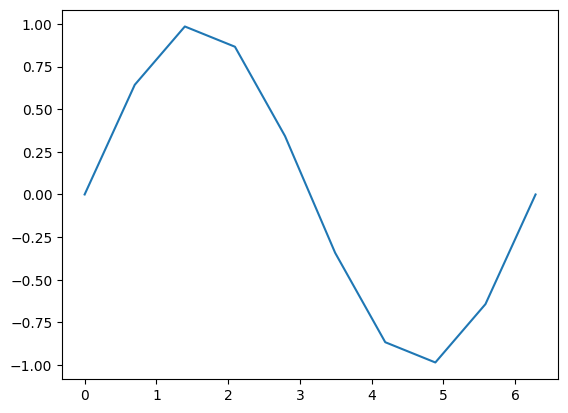

In [ ]:
import matplotlib.pyplot as plt
plt.plot(x, f)

**Логарифмы и экспоненты:**

In [ ]:
values = np.array([1, 2, 10])

print(np.exp(values))   # [2.718 7.389 22026.465] (e^x)
print(np.log(values))   # [0. 0.693 2.302] (натуральный логарифм)
print(np.log10(values)) # [0. 0.301 1.] (десятичный логарифм)
print(np.log2(values)) # [0. 0.301 1.] (двоичный логарифм)

In [ ]:
np.log(3)/np.log(4)

**Работа с массивами чисел (агрегирующие функции):**

In [ ]:
# help(np.std)

In [ ]:
lst = [2, 4, 5, 7]
min(lst), max(lst), sum(lst)

(2, 7, 18)

In [ ]:
N = 100000

In [ ]:
%%timeit
lst = range(N)
sum(lst)

2.75 ms ± 790 µs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [ ]:
%%timeit
lst = np.arange(N)
np.sum(lst)

83.5 µs ± 5.9 µs per loop (mean ± std. dev. of 7 runs, 10000 loops each)


In [ ]:
%%timeit
n = 5

19.3 ns ± 2.91 ns per loop (mean ± std. dev. of 7 runs, 10000000 loops each)


In [ ]:
2.75e-3 / 83.5e-6

32.93413173652694

In [ ]:
arr = np.array([1, 2, 3, 4, 5])

print(np.sum(arr))   # Сумма: 15
print(np.prod(arr))  # Произведение: 120
print(np.mean(arr))  # Среднее значение: 3.0
print(np.median(arr))  # Медианное значение: 3.0
print(np.var(arr))   # Дисперсия: 2.0
print(np.std(arr))   # Среднеквадратичное отклонение: 1.414
print(np.min(arr))   # Минимум: 1
print(np.max(arr))   # Максимум: 5

15
120
3.0
3.0
2.0
1.4142135623730951
1
5


In [ ]:
1, 4, 5, 7, 8, 9,

In [ ]:
print(np.unique([2, 2, 5, 5]))  # Уникальные значения: [2 5]

[2 5]


In [ ]:
Arr = np.array([[1, 2, 3, 4, 5], [1, 2, 3, 4, 5]])
Arr

array([[1, 2, 3, 4, 5],
       [1, 2, 3, 4, 5]])

In [ ]:
print(np.sum(Arr, axis=1))
print(np.sum(Arr, axis=0))
print(np.sum(Arr))

[15 15]
[ 2  4  6  8 10]
30


In [ ]:
print(np.unique(Arr, axis=0)[0].shape)
np.unique(Arr, axis=0)

(5,)


array([[1, 2, 3, 4, 5]])

In [ ]:
assert np.unique(Arr, axis=0)[0].shape[0] == 5

---
### 📝 Практика

**Задача 2.1. Min-max нормализация.**
Признаки с разным масштабом мешают моделям, поэтому их часто «сжимают» в диапазон $[0, 1]$ по формуле
$$x' = \frac{x - \min(x)}{\max(x) - \min(x)}.$$
Примените её к вектору [10, 20, 30, 40, 50].

In [ ]:
x = np. array([10, 20, 30, 40, 50])
x_norm = (x - x. min()) / (x. max() - x. min())
print(x_norm)

[0.   0.25 0.5  0.75 1.  ]


In [ ]:
x. max() - x. min()

np.int64(40)

**Задача 2.2. Стандартизация (z-score).**
Другой популярный способ привести признак к единому масштабу - вычесть среднее и поделить на стандартное отклонение: $z = \dfrac{x - \mu}{\sigma}$. После этого у признака среднее 0 и разброс 1. Стандартизируйте вектор [4, 8, 15, 16, 23, 42].

In [ ]:
x = np. array([4, 8, 15, 16, 23, 42])
x_std = (x - np.mean(x)) / np.std(x)
print(x_std)

[-1.13679712 -0.81199794 -0.24359938 -0.16239959  0.40599897  1.94879506]


**Задача 2.3. RMSE.**
Чтобы понять, насколько хороши предсказания регрессии, считают корень из среднеквадратичной ошибки:
$$RMSE = \sqrt{\frac{1}{n}\sum_{i}(y_i - \hat{y}_i)^2}.$$
Даны истинные значения [3, 5, 2, 7] и предсказания [2.5, 5.5, 2, 8] - посчитайте RMSE.

**Задача 2.4. Косинусная близость.**
Чтобы понять, насколько похожи два товара по их эмбеддингам, смотрят на угол между векторами - косинусную близость:
$$\cos(a, b) = \frac{a \cdot b}{\|a\| \, \|b\|}.$$
Посчитайте её для векторов [1, 2, 3] и [2, 4, 6]. Какое значение вы ожидаете получить и почему?

**Задача 2.5. Сигмоида.**
Сигмоида превращает любое число в значение от 0 до 1 (например, в вероятность класса в логистической регрессии): $\sigma(z) = \dfrac{1}{1 + e^{-z}}$. Примените её к вектору [-2, 0, 2] и проверьте, что в нуле получается ровно 0.5.

**Задача 2.6. Softmax.**
Там, где классов несколько, сырые выходы модели (логиты) превращают в вероятности через softmax:
$$\text{softmax}(z)_i = \frac{e^{z_i}}{\sum_j e^{z_j}}.$$
Переведите логиты [2.0, 1.0, 0.1] в вероятности и убедитесь, что они суммируются в единицу. Подсказка: чтобы не словить переполнение, перед экспонентой удобно вычесть максимум.

## 🟢 3. Математические операции с матрицами

Внимание! Все операции для векторов работают и для матриц - и важно учесть, что и применяться они будут точно так же - поэлементно (для суммы и вычитания это нормально, а умножение получится не настоящим "матричным").

В этом разделе рассмотрим более хитрые операции линейной алгебры непосредственно для матриц (включая вектор-строки и вектор-столбцы).

In [ ]:
A = np.array([[1, 2, 3],
              [4, 5, 6],
              [7, 8, 9]])
print("Матрица A:\n", A)

Матрица A:
 [[1 2 3]
 [4 5 6]
 [7 8 9]]


**Поэлементные операции с матрицами (из старого):**

In [ ]:
B = np.array([[9, 8, 7],
              [6, 5, 4],
              [3, 2, 1]])
print("Сумма:\n", A + B)  # Поэлементное сложение
print("Разность:\n", A - B)  # Поэлементное вычитание
print("Поэлементное умножение:\n", A * B)  # НЕ матричное умножение!

Сумма:
 [[10 10 10]
 [10 10 10]
 [10 10 10]]
Разность:
 [[-8 -6 -4]
 [-2  0  2]
 [ 4  6  8]]
Поэлементное умножение:
 [[ 9 16 21]
 [24 25 24]
 [21 16  9]]


**Матричное умножение:**

A{m, k} x B{n, l} ==> k == n

A{m, k} x B{k, l} = C{m, l}

In [ ]:
C = np.array([[1, 2],
              [3, 4],
              [5, 6]])
result = A @ C  # Матричное умножение (эквивалентно np.dot(A, C))
print("Результат A @ C:\n", result)

Результат A @ C:
 [[ 22  28]
 [ 49  64]
 [ 76 100]]


In [ ]:
# С.shape = (3, 2)
# (3, 2) x (3, 2)
C @ C

ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 3 is different from 2)

**Транспонирование:**

A --- a

A^T --- a^T

---

a{i, j} = a^T{j, i}

In [ ]:
print(A[1][1])
A

5


array([[1, 2, 3],
       [4, 5, 6],
       [7, 8, 9]])

In [ ]:
print(A[2][0])

7


In [ ]:
A_T = A.T # аналогичный результат от np.transpose(A)
print("Транспонированная матрица A:\n", A_T)
print("Исходная матрица A:\n", A)

Транспонированная матрица A:
 [[1 4 7]
 [2 5 8]
 [3 6 9]]
Исходная матрица A:
 [[1 2 3]
 [4 5 6]
 [7 8 9]]


In [ ]:
C_T = C.T # аналогичный результат от np.transpose(A)
print("Транспонированная матрица С:\n", C_T)
print("Исходная матрица С:\n", C)

Транспонированная матрица С:
 [[1 3 5]
 [2 4 6]]
Исходная матрица С:
 [[1 2]
 [3 4]
 [5 6]]


In [ ]:
C.T @ C # (2, 3) X (3, 2)

array([[35, 44],
       [44, 56]])

In [ ]:
# обратная матрица
np.linalg.inv(B)

LinAlgError: Singular matrix

In [ ]:
# псевдообратная матрица
np.linalg.pinv(C_T), np.linalg.pinv(B)

(array([[-1.33333333,  1.08333333],
        [-0.33333333,  0.33333333],
        [ 0.66666667, -0.41666667]]),
 array([[-1.94444444e-01,  1.66666667e-01,  5.27777778e-01],
        [ 5.55555556e-02, -4.39569489e-17, -5.55555556e-02],
        [ 3.05555556e-01, -1.66666667e-01, -6.38888889e-01]]))

Numpy умеет легко и просто решать **системы линейных уравнений** - достаточно задать матрицу системы и столбец свободных коэффициентов.

Ax = b

In [ ]:
A_sys = np.array([[2, 1],
                  [5, 3]])  # Коэффициенты уравнений

b = np.array([1, 4])  # Правая часть

solution = np.linalg.solve(A_sys, b)
print("Решение системы уравнений (x, y):", solution)

Решение системы уравнений (x, y): [-1.  3.]


In [ ]:
2*x + y = 1
3*y + 5*x = 4

In [ ]:
help(np.linalg.lstsq)

Help on _ArrayFunctionDispatcher in module numpy.linalg:

lstsq(a, b, rcond=None)
    Return the least-squares solution to a linear matrix equation.

    Computes the vector `x` that approximately solves the equation
    ``a @ x = b``. The equation may be under-, well-, or over-determined
    (i.e., the number of linearly independent rows of `a` can be less than,
    equal to, or greater than its number of linearly independent columns).
    If `a` is square and of full rank, then `x` (but for round-off error)
    is the "exact" solution of the equation. Else, `x` minimizes the
    Euclidean 2-norm :math:`||b - ax||`. If there are multiple minimizing
    solutions, the one with the smallest 2-norm :math:`||x||` is returned.

    Parameters
    ----------
    a : (M, N) array_like
        "Coefficient" matrix.
    b : {(M,), (M, K)} array_like
        Ordinate or "dependent variable" values. If `b` is two-dimensional,
        the least-squares solution is calculated for each of the `K` c

In [ ]:
# для переопределенных
np.linalg.lstsq(A_sys, b) # МНК

(array([-1.,  3.]),
 array([], dtype=float64),
 np.int32(2),
 array([6.24294338, 0.16018085]))

In [ ]:
# scipy

---
### 📝 Практика


**Задача 3.1. Линейный слой.**
Один слой нейросети - это умножение входов на матрицу весов плюс смещение: $out = XW + b$. Возьмите случайные входы $X$ формы (4, 3) и веса $W$ формы (3, 2), смещение $b = [0.1, 0.2]$. Посчитайте выход и его форму - она должна получиться (4, 2).

**Задача 3.2. Линейная регрессия по нормальному уравнению.**
Оптимальные веса линейной регрессии можно найти без всякого градиентного спуска - одной формулой:
$$w = (X^T X)^{-1} X^T y.$$
Дана матрица $X$ = [[1, 1], [1, 2], [1, 3]] (первый столбец - единицы для свободного члена) и $y$ = [1, 2, 3]. Найдите $w$.

In [ ]:
w = np.linalg.inv(X.T @ X) @ X.T @ y

**Задача 3.3. Матрица похожести товаров.**
В рекомендашках для блока «похожие товары» считают попарную косинусную близость сразу для всех товаров. Если строки матрицы эмбеддингов $E$ предварительно отнормировать на единичную длину, то вся матрица похожести - это просто $E E^T$. Сгенерируйте случайную $E$ формы (5, 3), отнормируйте строки и посчитайте матрицу попарных близостей (5, 5). Что должно стоять на диагонали?

## 🟢 4. Операции с изменением формы объектов

И последний раздел - про изменения, связанные с формой. Они редко относятся к математике, но могут пригодиться при формировании датасетов для анализа, обучения ML-моделей и т.п.

**Изменение формы массива (`reshape`)**

Позволяет изменить размерность массива без изменения данных.

*PS: `reshape` не всегда бывает возможным; нужно, чтобы кол-во элементов в массиве до и после были одинаковыми.*

In [ ]:
arr = np.arange(12)  # массив [0, 1, 2, ..., 11]
print(arr.shape)
print(arr)

(12,)
[ 0  1  2  3  4  5  6  7  8  9 10 11]


In [ ]:
reshaped = arr.reshape(2, 6)  # Делаем из него 3x4
print(reshaped.shape)
print(reshaped)

(2, 6)
[[ 0  1  2  3  4  5]
 [ 6  7  8  9 10 11]]


In [ ]:
arr.reshape((1, 12))

array([[ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11]])

In [ ]:
arr.reshape((12, 1))

array([[ 0],
       [ 1],
       [ 2],
       [ 3],
       [ 4],
       [ 5],
       [ 6],
       [ 7],
       [ 8],
       [ 9],
       [10],
       [11]])

In [ ]:
arr.reshape((1, 12)).T

**Объединение массивов (`concatenate`)**

Можно объединять массивы вдоль разных осей.

In [ ]:
a = np.array([[1, 2], [3, 4]])
b = np.array([[5, 6]])
print(a)
print(b)
a.shape, b.shape

[[1 2]
 [3 4]]
[[5 6]]


((2, 2), (1, 2))

In [ ]:
# По вертикали (добавляем строки)
vertical_concat = np.concatenate((b, a), axis=0)
print(vertical_concat)

[[5 6]
 [1 2]
 [3 4]]


In [ ]:
b.T

array([[5],
       [6]])

In [ ]:
# По горизонтали (добавляем столбцы)
horizontal_concat = np.concatenate((a, b.T), axis=1)
print(horizontal_concat)

[[1 2 5]
 [3 4 6]]


**Фильтрация элементов (np.where)**

Позволяет выбрать элементы, соответствующие условию.

In [ ]:
arr = np.array([10, 25, 8, 12, 30])
print(np.where(arr > 15))

filtered = arr[np.where(arr > 15)]  # Оставляем только элементы > 15
print(filtered)

(array([1, 4]),)
[25 30]


In [ ]:
arr > 15

array([False,  True, False, False,  True])

In [ ]:
np.where(arr > 15)

(array([1, 4]),)

In [ ]:
arr[[1, 4]]

array([25, 30])

In [ ]:
arr[0], arr[1]

**Основы срезов (`:`)**

В NumPy можно обращаться к элементам массива по индексам, а можно "вырезать" части массива с помощью срезов (slices).

*Тут теории побольше, разберём всё по порядку...*

**Базовый синтаксис:**

```
array[start:stop:step]
```

* `start` – индекс начала среза (включительно, по умолчанию 0)
* `stop` – индекс конца среза (не включается, по умолчанию конец массива)
* `step` – шаг, с которым выбираются элементы (по умолчанию 1)

Можно указать как все три аргумента при срезе, так и пропустить какие-либо из них. Если пропускаете шаг `step` - то можно просто его не писать; а если пропускаете начало `start` или конец `stop` - то важно прописать "пустые" двоеточия.

*Вот несколько примеров:*

In [ ]:
arr = np.array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
print(arr[1:4])  # [1, 2, 3] (элементы с индекса 1 до 3)
print(arr[1:6:2])  # [1, 3, 5] (элементы с индекса 1 до 6 с шагом 2)
print(arr[:5])   # [0 1 2 3 4]  – от начала до 5-го элемента (не включается)
print(arr[3:])   # [3 4 5 6 7 8 9]  – с 3-го элемента до конца
print(arr[::2])  # [0 2 4 6 8] – каждый второй элемент

[1 2 3]
[1 3 5]
[0 1 2 3 4]
[3 4 5 6 7 8 9]
[0 2 4 6 8]


Любопытно, что в Numpy индексы могут быть и отрицательными - это значит, что элементы будут браться не с начала, а с конца.

*Вот несколько примеров:*

In [ ]:
print(arr[-1])   # Выбираем последний элемент
print(arr[-2])   # Выбираем предпоследний элемент
print(arr[-3:])  # Срез последних трёх элементов
print(arr[:-2])  # Срез всех элементов, кроме последних двух
print(arr[::-1]) # Разворот массива

9
8
[7 8 9]
[0 1 2 3 4 5 6 7]
[9 8 7 6 5 4 3 2 1 0]


Абсолютно аналогичные правила работают и для срезов матриц, просто указываем отдельные "правила" для каждой оси в квадратных скобках через запятую:

```
array[start_row:end_row, start_col:end_col]
```

In [ ]:
arr = np.array([
    [1, 2, 3, 4],
    [5, 6, 7, 8],
    [9, 10, 11, 12]
])

print(arr[:2, :3])  # Берём первые 2 строки и первые 3 столбца
# [[1  2  3]
#  [5  6  7]]

print(arr[1:, 2:])  # С 1-й строки до конца, со 2-го столбца до конца
# [[ 7  8]
#  [11 12]]

---
### 📝 Практика


**Задача 4.1. Бинаризация по порогу.**
Классификатор выдаёт вероятности, а ответ нужен 0/1 - для этого ставят порог (обычно 0.5). Даны вероятности [0.2, 0.8, 0.55, 0.3, 0.95] - через np.where переведите их в метки классов по порогу 0.5.

**Задача 4.2. One-hot encoding.**
Категориальную метку класса часто превращают в вектор из нулей с единицей на нужной позиции. Красивый трюк: взять единичную матрицу и проиндексировать её метками. Закодируйте метки [0, 2, 1, 2] для 3 классов - должна получиться матрица (4, 3).

**Задача 4.3. Нормализация по столбцам.**
В реальном датасете нормализовать нужно каждый признак отдельно - то есть по столбцам. Для матрицы $X$ = [[1, 10], [2, 30], [3, 20]] примените min-max нормализацию по каждому столбцу (пригодится axis=0).

**Задача 4.4. Train/test split.**
Перед обучением данные делят на обучающую и тестовую части, предварительно перемешав. Для $X$ = np.arange(20).reshape(10, 2) перемешайте индексы строк (np.random.permutation) и разбейте на train (первые 8 объектов) и test (оставшиеся 2). Выведите их формы.

**Задача 4.5. Картинка в вектор признаков.**
Простые модели не умеют работать с двумерной картинкой - её «разворачивают» в один длинный вектор. Сгенерируйте «изображение» 8 $\times$ 8 из случайных яркостей (целые от 0 до 255) и превратите его в вектор признаков. Какой длины он получится?

## 🟢 5. Анализ ряда продаж

Сгенерируем данные и выполним базовый анализ.

In [ ]:
# help(np.random.normal)

In [ ]:
# генерация данных ряда продаж
np.random.seed(42)
n_days = 180

# линейный тренд
trend = np.linspace(50, 120, n_days)
# print(trend)

# недельная сезонность
seasonality = 10 * np.sin(np.arange(n_days) * 2 * np.pi / 7)
# print(seasonality)

# шум
noise = np.random.normal(0, 8, n_days)
# print(noise)

# итоговые продажи
sales = trend + seasonality + noise
# print(sales)

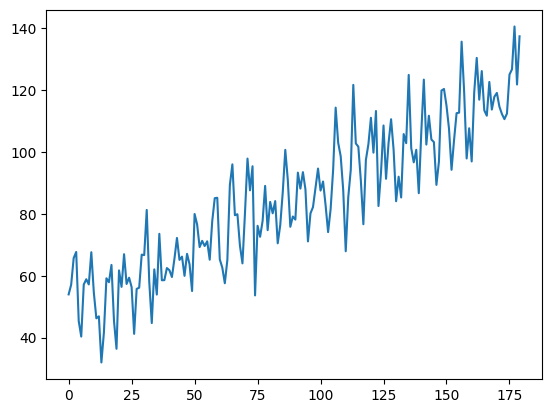

In [ ]:
plt.plot(sales)

In [ ]:
sales # продажи с 01.01.2026 по 01.07.2026

array([ 53.97371322,  57.10326187,  65.71291033,  67.6962606 ,
        45.35218142,  40.33293249,  57.16175641,  58.876908  ,
        57.19101136,  67.60931254,  54.54211037,  46.23700056,
        46.87915648,  31.9592421 ,  41.67551768,  59.18593638,
        57.9036134 ,  63.50086074,  45.43607615,  36.38245887,
        61.72810438,  56.4060801 ,  66.96189242,  57.34570704,
        59.36925046,  56.32507964,  41.21037002,  55.74592854,
        56.14461115,  66.82554695,  66.6674698 ,  81.2799679 ,
        58.06715129,  44.69406138,  62.05813386,  53.92040164,
        73.56743588,  58.54119187,  58.5736842 ,  62.48744914,
        61.80091162,  59.58615098,  65.49939475,  72.22512772,
        65.12780711,  66.17784909,  59.96487926,  67.08758696,
        63.70158121,  55.05768993,  79.96405921,  76.61275496,
        69.25865692,  71.2808299 ,  69.61603549,  71.14030602,
        65.18570116,  77.63511861,  85.08095082,  85.21582411,
        65.29145586,  62.62019767,  57.57681544,  65.06

In [ ]:
# Базовые статистики ряда
sales_min = sales.min() #np.min(sales)
sales_max = np.max(sales)
sales_mean = np.mean(sales)
sales_median = np.median(sales)
sales_std = np.std(sales)

print("Мин:", sales_min)
print("Макс:", sales_max)
print("Среднее:", sales_mean)
print("Медиана:", sales_median)
print("Стандартное отклонение:", sales_std)

Мин: 31.959242100738887
Макс: 140.59542883404882
Среднее: 84.92046745861428
Медиана: 84.61093158055797
Стандартное отклонение: 23.56651153572431


In [ ]:
help(np.convolve)

Help on _ArrayFunctionDispatcher in module numpy:

convolve(a, v, mode='full')
    Returns the discrete, linear convolution of two one-dimensional sequences.

    The convolution operator is often seen in signal processing, where it
    models the effect of a linear time-invariant system on a signal [1]_.  In
    probability theory, the sum of two independent random variables is
    distributed according to the convolution of their individual
    distributions.

    If `v` is longer than `a`, the arrays are swapped before computation.

    Parameters
    ----------
    a : (N,) array_like
        First one-dimensional input array.
    v : (M,) array_like
        Second one-dimensional input array.
    mode : {'full', 'valid', 'same'}, optional
        'full':
          By default, mode is 'full'.  This returns the convolution
          at each point of overlap, with an output shape of (N+M-1,). At
          the end-points of the convolution, the signals do not overlap
          complet

In [ ]:
# Скользящее среднее за 7 дней
window = 7
ma7 = np.convolve(sales, np.ones(window)/window, mode='valid')

print(ma7[:10])

[55.33328805 56.03374445 56.04628009 56.31719469 54.43803037 54.5644331
 55.49960796 51.89924877 49.4419073  49.72689659]


In [ ]:
np.ones(window)/window

array([0.14285714, 0.14285714, 0.14285714, 0.14285714, 0.14285714,
       0.14285714, 0.14285714])

In [ ]:
1 / 7

0.14285714285714285

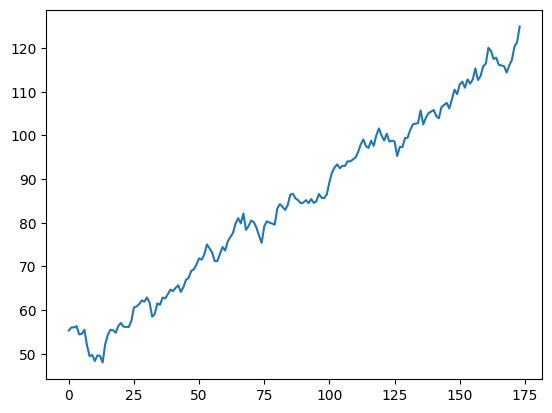

In [ ]:
plt.plot(ma7)

In [ ]:
# Выбросы (выше mean + 2*std)
threshold = sales_mean + 2 * sales_std
outliers_idx = np.where(sales > threshold)[0]

print("Количество выбросов:", len(outliers_idx))
print("Первые индексы выбросов:", outliers_idx[:10])

Количество выбросов: 3
Первые индексы выбросов: [156 177 179]


In [ ]:
threshold

np.float64(132.0534905300629)

In [ ]:
sales[outliers_idx]

array([135.6810618 , 140.59542883, 137.42251594])

In [ ]:
# Дни с минимальными продажами (топ-5 просадок)
lowest_5_idx = np.argsort(sales)[:5]

print("Топ-5 дней с минимальными продажами:", lowest_5_idx)
print("Значения:", sales[lowest_5_idx])

Топ-5 дней с минимальными продажами: [13 19  5 26 14]
Значения: [31.9592421  36.38245887 40.33293249 41.21037002 41.67551768]


In [ ]:
highest_5_idx = np.argsort(sales)[:-6:-1]

print("Топ-5 дней с максимальными продажами:", highest_5_idx)
print("Значения:", sales[highest_5_idx])

Топ-5 дней с максимальными продажами: [177 179 156 162 176]
Значения: [140.59542883 137.42251594 135.6810618  130.43903476 126.7491456 ]


---
### 📝 Практика


**Задача 5.1. Доля удачных дней.**
Посчитайте, в какой доле дней продажи оказались выше среднего по ряду. Подсказка: среднее по булевой маске - это и есть искомая доля. Ответ выведите в процентах.

**Задача 5.2. Нормализация ряда.**
Приведите ряд продаж sales к диапазону $[0, 1]$ той же min-max формулой, что и в задаче 2.1, и выведите первые 5 значений. Так ряды разного масштаба становится удобно сравнивать на одном графике.